# Project 1: compact ResNet on CIFAR-10

**Author:** Shenghua Huang. The model is trained from scratch using only the course competition images. This notebook displays the saved experiment under `results/cifar_resnet_w40/`. To reproduce a fresh run from the project root, use one empty output directory for every command:

```powershell
uv run --extra notebook python train.py --epochs 100 --batch-size 128 --workers 0 --output runs/reproduction-001
uv run --extra notebook python plot_metrics.py --run runs/reproduction-001
uv run --extra notebook python evaluate.py --run runs/reproduction-001
uv run --extra notebook python predict.py --checkpoint runs/reproduction-001/best.pt --output submission_reproduction.csv
uv run --extra notebook python evaluate.py --run runs/reproduction-001 --tta-flip
uv run --extra notebook python predict.py --checkpoint runs/reproduction-001/best.pt --tta-flip --output submission_reproduction_flip_tta.csv
```

The source repository excludes raw images, API tokens, prediction CSVs, and large checkpoints.

## 1. Configuration and parameter budget

The model uses a CIFAR-sized stem and four residual stages. The next cell executes the model code and prints the exact trainable parameter count.

In [1]:
import csv, json, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'models' / 'resnet.py').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'models' / 'resnet.py').is_file(), 'Open this notebook from the project root or notebooks folder'
sys.path.insert(0, str(ROOT))
from models.resnet import CifarResNet, count_parameters
run = ROOT / 'results' / 'cifar_resnet_w40'
config = json.loads((run / 'config.json').read_text(encoding='utf-8'))
model = CifarResNet(config['width'])
parameters = count_parameters(model)
print('Architecture: 3x3 stem; 2 residual blocks per stage; widths 40, 80, 160, 320')
print(f'Trainable parameters: {parameters:,} / 5,000,000')
print(f'Training / validation images: {config["train_size"]:,} / {config["validation_size"]:,}')
print(f'Seed: {config["seed"]}; epochs: {config["epochs"]}; batch size: {config["batch_size"]}')
assert parameters == config['trainable_parameters'] and parameters <= 5_000_000

Architecture: 3x3 stem; 2 residual blocks per stage; widths 40, 80, 160, 320
Trainable parameters: 4,368,690 / 5,000,000
Training / validation images: 45,000 / 5,000
Seed: 42; epochs: 100; batch size: 128


## 2. Learning curves

These cells execute directly from the per-epoch metrics produced by `train.py`. Validation labels were held out before training.

Completed epochs: 100 / 100
Best held-out validation accuracy: 94.82% at epoch 96


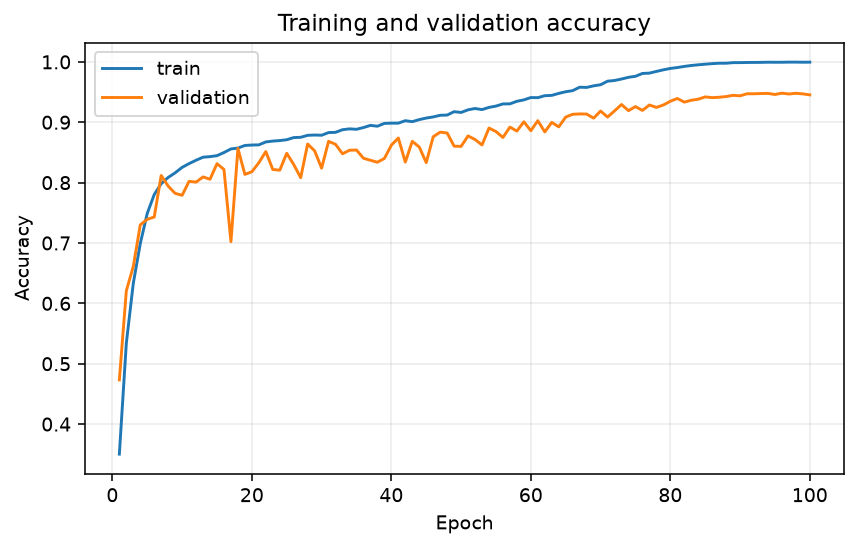

In [2]:
import matplotlib.pyplot as plt
with (run / 'metrics.csv').open(newline='', encoding='utf-8') as stream:
    metrics = list(csv.DictReader(stream))
epochs = [int(row['epoch']) for row in metrics]
train_accuracy = [float(row['train_accuracy']) for row in metrics]
val_accuracy = [float(row['val_accuracy']) for row in metrics]
best_index = max(range(len(metrics)), key=lambda i: val_accuracy[i])
print(f'Completed epochs: {len(metrics)} / {config["epochs"]}')
print(f'Best held-out validation accuracy: {val_accuracy[best_index]:.2%} at epoch {epochs[best_index]}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, train_accuracy, label='train')
ax.plot(epochs, val_accuracy, label='validation')
ax.set(xlabel='Epoch', ylabel='Accuracy', title='Training and validation accuracy')
ax.grid(alpha=.25); ax.legend(); plt.show()

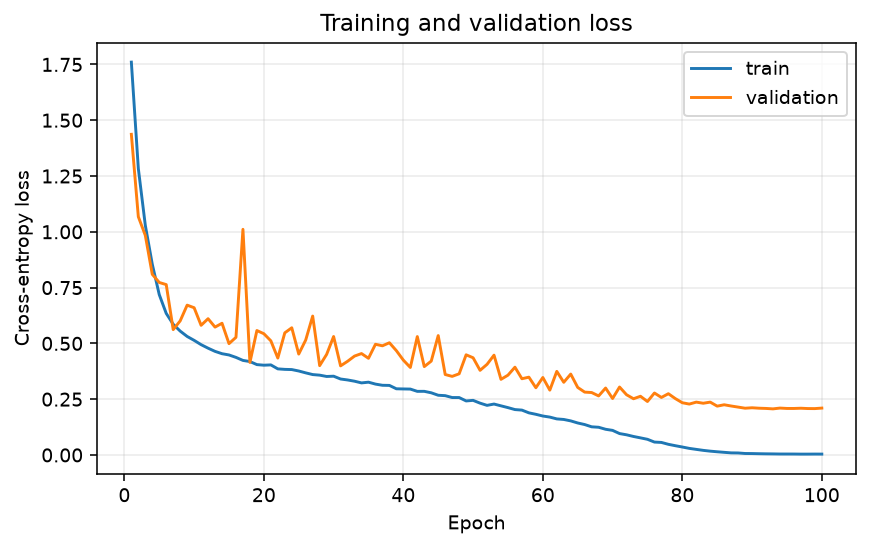

In [3]:
train_loss = [float(row['train_loss']) for row in metrics]
val_loss = [float(row['val_loss']) for row in metrics]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, train_loss, label='train')
ax.plot(epochs, val_loss, label='validation')
ax.set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Training and validation loss')
ax.grid(alpha=.25); ax.legend(); plt.show()

## 3. Validation error analysis

The confusion matrix is computed by `evaluate.py` from the best checkpoint and the same fixed validation IDs.

Held-out validation accuracy by class:
  airplane: 94.20% (471/500)
automobile: 97.60% (488/500)
      bird: 95.00% (475/500)
       cat: 89.80% (449/500)
      deer: 95.80% (479/500)
       dog: 90.20% (451/500)
      frog: 95.20% (476/500)
     horse: 95.80% (479/500)
      ship: 97.00% (485/500)
     truck: 97.60% (488/500)


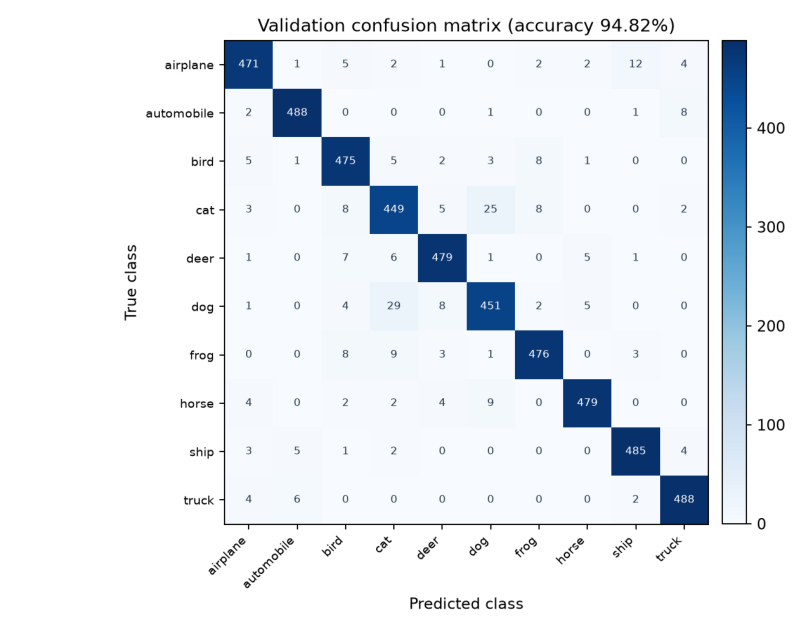

In [4]:
with (run / 'per_class.csv').open(newline='', encoding='utf-8') as stream:
    per_class = list(csv.DictReader(stream))
print('Held-out validation accuracy by class:')
for row in per_class:
    print(f'{row["class"]:>10}: {float(row["accuracy"]):6.2%} ({row["correct"]}/{row["total"]})')
image = plt.imread(run / 'confusion.png')
fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.imshow(image); ax.axis('off'); plt.show()

## 4. Submission checks and final test accuracy

I checked that both prediction files matched Kaggle's required format before submitting them. The saved output shows those checks. If you reproduce the run, this cell can check your new CSVs against the competition's sample submission. The final score below comes from my Kaggle leaderboard entry.

In [5]:
with (run / 'kaggle_submissions.csv').open(newline='', encoding='utf-8') as stream:
    submission_records = list(csv.DictReader(stream))
historical_files = {'single_view': 'submission.csv', 'horizontal_flip_tta': 'submission_flip_tta.csv'}
reproduction_files = {
    'single_view': 'submission_reproduction.csv',
    'horizontal_flip_tta': 'submission_reproduction_flip_tta.csv',
}
assert {item['method'] for item in submission_records} == set(historical_files)
sample_path = ROOT / 'data' / 'sample_submission.csv'
if sample_path.is_file():
    with sample_path.open(newline='', encoding='utf-8') as stream:
        sample = list(csv.DictReader(stream))
else:
    sample = None
    print('Competition sample CSV is absent in this checkout; regenerate predictions after obtaining the permitted data.')

def check_predictions(path):
    with path.open(newline='', encoding='utf-8') as stream:
        predictions = list(csv.DictReader(stream))
    assert sample is not None
    assert len(predictions) == len(sample) == 2000
    assert list(predictions[0]) == ['id', 'label']
    assert [row['id'] for row in predictions] == [row['id'] for row in sample]
    assert all(row['label'] in {str(i) for i in range(10)} for row in predictions)
    return len(predictions)

for item in submission_records:
    method = item['method']
    historical_name = item['file_name']
    assert historical_name == historical_files[method]
    historical = ROOT / historical_name
    if historical.is_file() and sample is not None:
        count = check_predictions(historical)
        print(f'Historical {historical_name}: {count} valid predictions; Kaggle submission {item["submission_ref"]}; public score {float(item["public_score"]):.2%}')
    elif not historical.is_file():
        print(f'Historical {historical_name}: omitted from Git; the saved notebook output documents the original check and Kaggle score.')
    else:
        print(f'Historical {historical_name}: present, but sample_submission.csv is needed to recheck its format.')
    fresh = ROOT / reproduction_files[method]
    if fresh.is_file() and sample is not None:
        count = check_predictions(fresh)
        print(f'Fresh reproduction {fresh.name}: {count} valid predictions; no Kaggle score is assigned to this new file.')
    elif not fresh.is_file():
        print(f'Fresh reproduction {fresh.name}: absent; run the prediction command above after obtaining competition data.')
    else:
        print(f'Fresh reproduction {fresh.name}: present, but sample_submission.csv is needed to recheck its format.')

Historical submission.csv: 2000 valid predictions; Kaggle submission 57801555; public score 83.00%
Fresh reproduction submission_reproduction.csv: absent; run the prediction command above after obtaining competition data.
Historical submission_flip_tta.csv: 2000 valid predictions; Kaggle submission 57802204; public score 83.60%
Fresh reproduction submission_reproduction_flip_tta.csv: absent; run the prediction command above after obtaining competition data.


In [6]:
score = json.loads((ROOT / 'kaggle_score.json').read_text(encoding='utf-8'))
winner = max(submission_records, key=lambda item: float(item['private_score']))
assert score['kind'] == 'private' and score['accuracy'] == float(winner['private_score'])
assert score['file_name'] == winner['file_name']
print(f'Final Test Accuracy (Kaggle private leaderboard): {score["accuracy"]:.2%}')
print(f'Submission: {score["file_name"]}')
print(f'Number of Parameters (trainable): {parameters:,}')

Final Test Accuracy (Kaggle private leaderboard): 81.30%
Submission: submission_flip_tta.csv
Number of Parameters (trainable): 4,368,690


## 5. Comparing my submissions

I used the same checkpoint for both submissions. For the second, I averaged the logits from each image and its horizontal flip before picking a class. The private score went from 80.20% to 81.30%, so the flip-TTA submission gave me my final score.

In [7]:
for item in submission_records:
    print(f'{item["file_name"]}: validation {float(item["validation_accuracy"]):.2%}; '
          f'public {float(item["public_score"]):.2%}; private {float(item["private_score"]):.2%}')

submission.csv: validation 94.82%; public 83.00%; private 80.20%
submission_flip_tta.csv: validation 95.20%; public 83.60%; private 81.30%


## 6. A short training check

I ran `train.py` for one epoch with only five training batches to show the training pipeline in action. The script still evaluates the full validation split. The numbers from this check are separate from my 100-epoch competition run above. It uses the local competition data and writes to a new directory under `runs/`.

In [8]:
import subprocess
from uuid import uuid4

if (ROOT / 'data' / 'train_labels.csv').is_file():
    output_dir = Path('runs') / f'smoke-test-{uuid4().hex[:8]}'
    command = [sys.executable, 'train.py', '--epochs', '1', '--max-batches', '5',
               '--output', str(output_dir)]
    run_check = subprocess.run(command, cwd=ROOT, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True)
    log = run_check.stdout.replace(str(ROOT / output_dir), str(output_dir))
    if run_check.returncode:
        raise RuntimeError(log)
    print(log, end='')
else:
    print('The training check needs local competition data. See the README for setup.')

Device: cuda; train: 45000; validation: 5000; trainable parameters: 4,368,690
Run directory: runs\smoke-test-5d30807d
epoch 001/1: train 12.03%, val 13.38%, best 13.38%, loss 2.8688, 22.9s
Final best validation accuracy: 13.38%
Trainable parameters: 4,368,690


## Reference

K. He, X. Zhang, S. Ren, and J. Sun, [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385), CVPR 2016. The implementation in this repository was written for this project.